# Extremum graph: maxima and saddles

This notebook runs `pipeline/extremum_graph.py` and draws the result with
matplotlib and networkx.

1. A five-point example you can check by hand.
2. `cyclic_2d`: six peaks in a ring, compared with the generator's ground truth.
3. How the neighbour count `k` and the persistence threshold change the result.
4. `cyclic_3d` and the controlled-extrema datasets.

**Reading the pictures.** Orange triangles are maxima (peaks), blue squares
are saddles, and each saddle is joined by a line to the two peaks it links.
Grey dots are the data points, darker means a higher value.

In [1]:
import sys, pathlib
ROOT = pathlib.Path.cwd().resolve()
if not (ROOT / "pipeline").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

import numpy as np
import matplotlib.pyplot as plt
import networkx as nx
import matplotlib.patheffects as pe

from pipeline.data_loader import load_dataset
from pipeline.neighbor_graph import NeighborGraph, knn_graph
from pipeline.extremum_graph import extremum_graph

plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#888888", "axes.labelcolor": "#333333",
    "xtick.color": "#555555", "ytick.color": "#555555", "text.color": "#222222",
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left",
})
PEAK, SADDLE, LINK = "#D55E00", "#0072B2", "#555555"
REGION = ["#D55E00", "#0072B2", "#009E73", "#CC79A7", "#E69F00", "#56B4E9"]  # fixed order

In [2]:
def draw_on_data(ax, ds, eg, dims=(0, 1), points=True, title=""):
    """Data points (grey by value) with the extremum graph drawn on top."""
    P = ds.points[:, list(dims)]
    if points:
        ax.scatter(P[:, 0], P[:, 1], c=ds.values, cmap="Greys", s=3, vmin=0, vmax=1.7,
                   alpha=0.6, linewidths=0, rasterized=True)
    for peak_id, sad_id in eg.edges:
        a, b = P[eg.peaks[peak_id]], P[eg.saddles[sad_id]]
        ax.plot([a[0], b[0]], [a[1], b[1]], color="#222222", lw=1.8, zorder=2,
                path_effects=[pe.Stroke(linewidth=4.5, foreground="white"), pe.Normal()])
    ax.scatter(*P[eg.saddles].T, marker="s", s=70, c=SADDLE, edgecolors="white",
               linewidths=1.5, zorder=3, label=f"saddle ({eg.num_saddles})")
    ax.scatter(*P[eg.peaks].T, marker="^", s=110, c=PEAK, edgecolors="white",
               linewidths=1.5, zorder=4, label=f"maximum ({eg.num_peaks})")
    for i, v in enumerate(eg.peaks):
        ax.annotate(str(i), P[v], xytext=(6, 6), textcoords="offset points", fontsize=9, zorder=5)
    ax.set_aspect("equal"); ax.set_title(title)
    ax.set_xlabel(f"x{dims[0]}"); ax.set_ylabel(f"x{dims[1]}")
    ax.legend(loc="upper right", frameon=True, framealpha=0.9, fontsize=8)


def draw_regions(ax, ds, eg, dims=(0, 1), title=""):
    """Each data point coloured by the peak it climbs to."""
    P = ds.points[:, list(dims)]
    colors = np.array(REGION)[eg.region % len(REGION)]
    ax.scatter(P[:, 0], P[:, 1], c=colors, s=3, linewidths=0, rasterized=True)
    ax.scatter(*P[eg.peaks].T, marker="^", s=110, c="white", edgecolors="#222222",
               linewidths=1.2, zorder=4)
    for i, v in enumerate(eg.peaks):
        ax.annotate(f"{i}  ({eg.region_size[i]:,} pts)", P[v], xytext=(7, 7),
                    textcoords="offset points", fontsize=8, zorder=5,
                    bbox=dict(boxstyle="round,pad=0.15", fc="white", ec="none", alpha=0.8))
    ax.set_aspect("equal"); ax.set_title(title)
    ax.set_xlabel(f"x{dims[0]}"); ax.set_ylabel(f"x{dims[1]}")


def to_networkx(eg):
    G = nx.Graph()
    for i in range(eg.num_peaks):
        G.add_node(("peak", i), kind="peak", size=int(eg.region_size[i]))
    for j in range(eg.num_saddles):
        G.add_node(("saddle", j), kind="saddle")
    for p, s in eg.edges:
        G.add_edge(("peak", int(p)), ("saddle", int(s)))
    return G


def draw_networkx(ax, eg, pos=None, layout="spring", dims=None, ds=None, title=""):
    """The extremum graph as a plain graph. Peak size follows the number of points it holds."""
    G = to_networkx(eg)
    if pos is None:
        if layout == "data":                     # use the real positions of the points
            P = ds.points[:, list(dims)]
            pos = {("peak", i): P[v] for i, v in enumerate(eg.peaks)}
            pos.update({("saddle", j): P[v] for j, v in enumerate(eg.saddles)})
        else:
            pos = nx.spring_layout(G, seed=3, k=1.2, iterations=200)
    peaks = [n for n in G if n[0] == "peak"]
    saddles = [n for n in G if n[0] == "saddle"]
    smax = max(G.nodes[n]["size"] for n in peaks) or 1
    nx.draw_networkx_edges(G, pos, ax=ax, edge_color=LINK, width=1.6)
    nx.draw_networkx_nodes(G, pos, nodelist=saddles, node_shape="s", node_size=110,
                           node_color=SADDLE, edgecolors="white", linewidths=1.5, ax=ax)
    nx.draw_networkx_nodes(G, pos, nodelist=peaks, node_shape="^", edgecolors="white",
                           node_size=[250 + 1400 * G.nodes[n]["size"] / smax for n in peaks],
                           node_color=PEAK, linewidths=1.5, ax=ax)
    nx.draw_networkx_labels(G, pos, labels={n: str(n[1]) for n in peaks}, font_size=9,
                            font_color="white", font_weight="bold", ax=ax)
    ax.set_title(title); ax.set_axis_off(); ax.margins(0.12)
    if layout == "data": ax.set_aspect("equal")
    return pos

## 1. A five-point example

Five samples on a line. Each point is connected to its neighbours, and the
numbers are the field values:

```
A —— B —— C —— D —— E
9     4     7     3     8
```

Peaks should be A, C and E. B and D are the valleys between them, so they
are the saddles. By hand: C rises 3 above B, and E rises 5 above D, so those
are their persistences.

In [3]:
names = list("ABCDE")
vals = np.array([9, 4, 7, 3, 8], dtype=float)
path = NeighborGraph.from_edges(5, np.array([[0, 1], [1, 2], [2, 3], [3, 4]]))

eg = extremum_graph(vals, path)
print(eg, "\n")

print("peak id  point  value  persistence  points in its region")
for i, v in enumerate(eg.peaks):
    pers = "inf (global max)" if np.isinf(eg.peak_persistence[i]) else f"{eg.peak_persistence[i]:.0f}"
    members = "".join(names[j] for j in np.flatnonzero(eg.region == i))
    print(f"   {i}       {names[v]}     {vals[v]:.0f}    {pers:<16}  {members}")

print("\nsaddle  point  value  links peaks   kind")
for s, v in enumerate(eg.saddles):
    a, b = eg.saddle_peaks[s]
    print(f"   {s}      {names[v]}     {vals[v]:.0f}    {names[eg.peaks[a]]} and {names[eg.peaks[b]]}"
          f"       {'merge' if eg.saddle_is_merge[s] else 'closes a loop'}")

# These are the numbers worked out by hand above.
assert [names[v] for v in eg.peaks] == ["A", "E", "C"]
assert [names[v] for v in eg.saddles] == ["B", "D"]
assert eg.peak_persistence[2] == 3 and eg.peak_persistence[1] == 5 and np.isinf(eg.peak_persistence[0])

ExtremumGraph(3 peaks, 2 saddles (0 close a loop), N=5) 

peak id  point  value  persistence  points in its region
   0       A     9    inf (global max)  AB
   1       E     8    5                 DE
   2       C     7    3                 C

saddle  point  value  links peaks   kind
   0      B     4    A and C       merge
   1      D     3    E and C       merge


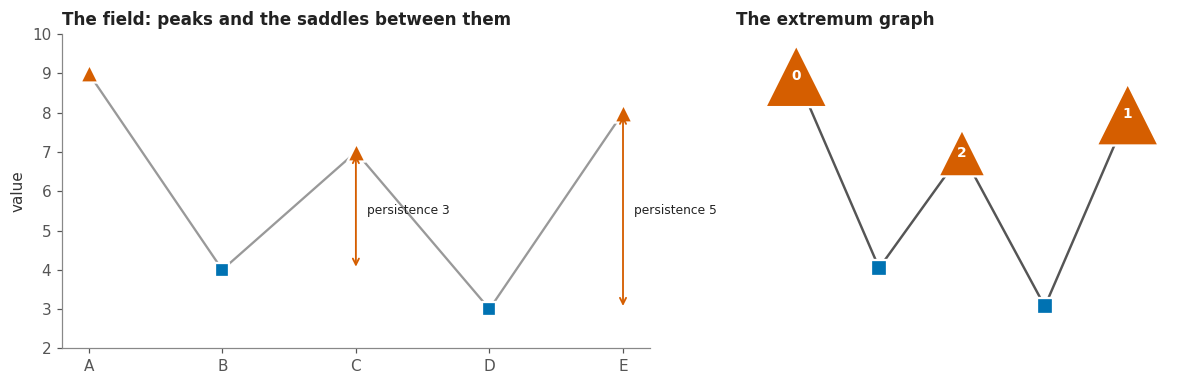

In [4]:
fig, (a, b) = plt.subplots(1, 2, figsize=(11, 3.6), gridspec_kw={"width_ratios": [1.3, 1]})

x = np.arange(5)
a.plot(x, vals, color="#999999", lw=1.5, zorder=1)
a.scatter(x, vals, s=25, color="#999999", zorder=2)
a.scatter(x[eg.peaks], vals[eg.peaks], marker="^", s=140, c=PEAK, edgecolors="white", linewidths=1.5, zorder=3)
a.scatter(x[eg.saddles], vals[eg.saddles], marker="s", s=90, c=SADDLE, edgecolors="white", linewidths=1.5, zorder=3)
for i, v in enumerate(eg.peaks):
    if np.isfinite(eg.peak_persistence[i]):
        s = eg.saddles[np.argmax((eg.saddle_peaks == i).any(1) & eg.saddle_is_merge)]
        a.annotate("", (v, vals[v]), (v, vals[s]), arrowprops=dict(arrowstyle="<->", color=PEAK, lw=1.2))
        a.text(v + 0.08, (vals[v] + vals[s]) / 2, f"persistence {eg.peak_persistence[i]:.0f}", fontsize=8, va="center")
a.set_xticks(x, names); a.set_ylabel("value"); a.set_ylim(2, 10)
a.set_title("The field: peaks and the saddles between them")

draw_networkx(b, eg, pos={**{("peak", i): (v, vals[v]) for i, v in enumerate(eg.peaks)},
                          **{("saddle", j): (v, vals[v]) for j, v in enumerate(eg.saddles)}},
              title="The extremum graph")
plt.tight_layout(); plt.show()

Peak ids count from the highest peak: 0 is A, 1 is E and 2 is C. Each
saddle is joined to the peaks of the two regions that touch at it. D
touches the region of C and the region of E, so it links C and E. The
persistence of E (5) is measured from D, the highest saddle that connects E
to a higher peak.

## 2. Six peaks in a ring (`cyclic_2d`)

20,000 random points. The field is a ring with six equal bumps, so the right
answer is **6 peaks and 6 saddles**, and the graph is a **loop**: each peak
is linked to its two neighbours along the ring.

`k` is the number of nearest neighbours used to connect the points. Any value
works. We use 20 here.

In [5]:
ds = load_dataset("cyclic_2d")
graph = knn_graph(ds.points, k=20)
eg = extremum_graph(ds.values, graph)
print(ds); print(graph); print(eg)

Dataset('cyclic_2d', mode=cyclic_ring, N=20000, d=2, values=[0.000, 1.000], ground_truth: 6 max, 6 saddle)
NeighborGraph(N=20000, E=220664, degree min/mean/max=20/22.1/36)
ExtremumGraph(6 peaks, 6 saddles (1 close a loop), N=20000)


In [6]:
def edge_set(ds, eg):
    """Found graph as pairs (truth max id, truth saddle id), matching by nearest ground-truth point."""
    tmax, tsad = ds.centers("max"), ds.centers("saddle")
    nearest = lambda c, q: int(np.argmin(np.linalg.norm(c - q, axis=1)))
    pm = [nearest(tmax, ds.points[v]) for v in eg.peaks]
    sm = [nearest(tsad, ds.points[v]) for v in eg.saddles]
    return {(ds.maxima[pm[p]].id, ds.saddles[sm[s]].id) for p, s in eg.edges}

def truth_edge_set(ds):
    out = set()
    for a, b in ds.extremum_graph_edges:
        out.add((b, a) if a.startswith("saddle") else (a, b))
    return out

def compare_with_truth(ds, eg):
    for kind, truth, found in (("maximum", ds.maxima, eg.peaks), ("saddle", ds.saddles, eg.saddles)):
        print(f"{kind:8s} truth id   truth location        nearest found point   distance (first 3 coordinates shown)")
        for t in truth:
            d = np.linalg.norm(ds.points[found] - t.center, axis=1)
            j = int(np.argmin(d))
            show = lambda x: np.array2string(np.round(x[:3], 2) + 0.0, precision=2, suppress_small=True)
            print(f"         {t.id:10s} {show(t.center):22s}  {show(ds.points[found[j]]):22s}  {d[j]:.3f}")
    f, t = edge_set(ds, eg), truth_edge_set(ds)
    print(f"\nedges: found {len(f)}, truth {len(t)}, identical sets: {f == t}")

compare_with_truth(ds, eg)

maximum  truth id   truth location        nearest found point   distance (first 3 coordinates shown)
         max_0      [2.5 0. ]               [ 2.52 -0.01]           0.021
         max_1      [1.25 2.17]             [1.21 2.17]             0.043
         max_2      [-1.25  2.17]           [-1.28  2.17]           0.033
         max_3      [-2.5  0. ]             [-2.47  0.  ]           0.034
         max_4      [-1.25 -2.17]           [-1.24 -2.14]           0.026
         max_5      [ 1.25 -2.17]           [ 1.24 -2.13]           0.038
saddle   truth id   truth location        nearest found point   distance (first 3 coordinates shown)
         saddle_0   [2.17 1.25]             [2.23 1.2 ]             0.082
         saddle_1   [0.  2.5]               [0.07 2.53]             0.076
         saddle_2   [-2.17  1.25]           [-2.18  1.18]           0.067
         saddle_3   [-2.17 -1.25]           [-2.15 -1.17]           0.083
         saddle_4   [ 0.  -2.5]             [ 0.03 -2.55] 

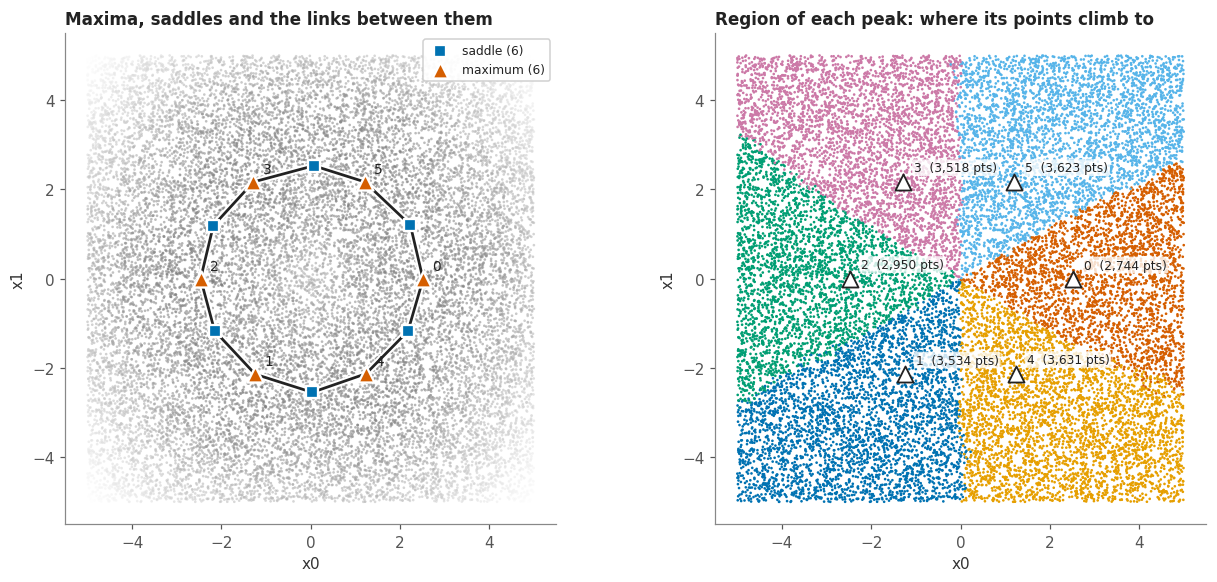

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5.4))
draw_on_data(axes[0], ds, eg, title="Maxima, saddles and the links between them")
draw_regions(axes[1], ds, eg, title="Region of each peak: where its points climb to")
plt.tight_layout(); plt.show()

The same graph with the data removed. On the left the nodes sit where the
points are, on the right a force-directed layout places them with no spatial
information. Both show a single loop of six peaks and six saddles.

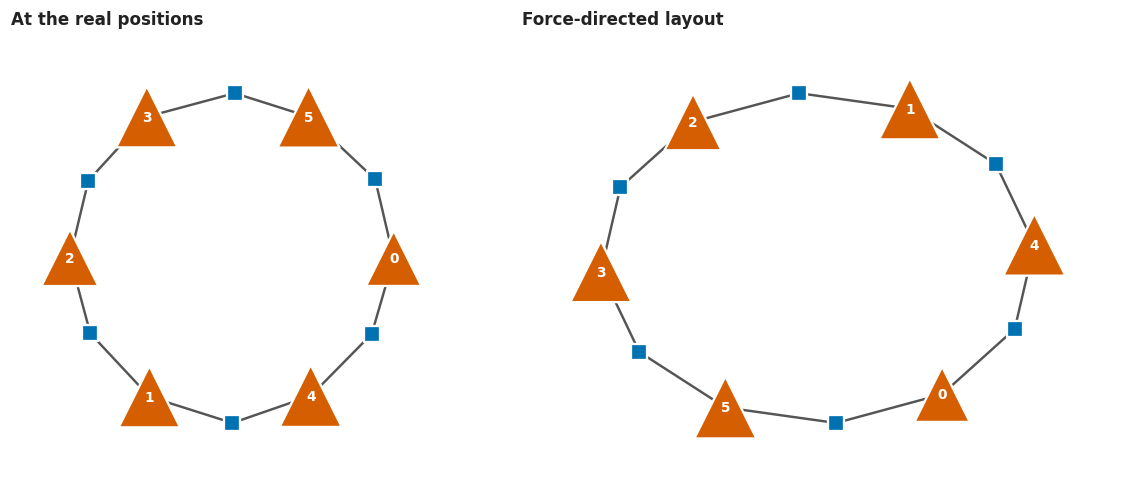

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.6))
draw_networkx(axes[0], eg, layout="data", ds=ds, dims=(0, 1), title="At the real positions")
draw_networkx(axes[1], eg, layout="spring", title="Force-directed layout")
plt.tight_layout(); plt.show()

## 3. Noise, `k` and the persistence threshold

With a smaller `k` the neighbour graph has more small bumps, and each bump
becomes a peak. The peaks are all there but most have very low persistence,
so we measure persistence and drop the small ones with `simplify`.

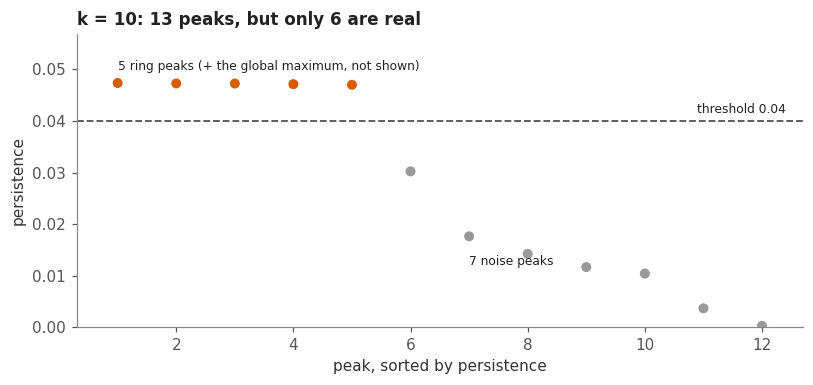

In [9]:
ds = load_dataset("cyclic_2d")
eg10 = extremum_graph(ds.values, knn_graph(ds.points, k=10))
pers = np.sort(eg10.peak_persistence[np.isfinite(eg10.peak_persistence)])[::-1]
THRESHOLD = 0.04

fig, ax = plt.subplots(figsize=(7.5, 3.6))
ax.scatter(np.arange(1, len(pers) + 1), pers, s=60, c=np.where(pers >= THRESHOLD, PEAK, "#999999"),
           edgecolors="white", linewidths=1.2, zorder=3)
ax.axhline(THRESHOLD, color=LINK, lw=1.2, ls="--")
ax.text(len(pers) + 0.4, THRESHOLD + 0.001, f"threshold {THRESHOLD}", ha="right", va="bottom", fontsize=8)
ax.text(1.0, pers[0] + 0.002, "5 ring peaks (+ the global maximum, not shown)", fontsize=8, va="bottom")
ax.text(len(pers) / 2 + 1, 0.012, f"{int((pers < THRESHOLD).sum())} noise peaks", fontsize=8)
ax.xaxis.set_major_locator(plt.MaxNLocator(integer=True))
ax.set_xlabel("peak, sorted by persistence"); ax.set_ylabel("persistence")
ax.set_title(f"k = 10: {eg10.num_peaks} peaks, but only 6 are real")
ax.set_xlim(0.3, len(pers) + 0.7); ax.set_ylim(0, pers[0] * 1.2)
plt.tight_layout(); plt.show()

In [10]:
def sweep_k(name, ks, threshold=THRESHOLD):
    ds = load_dataset(name)
    truth = truth_edge_set(ds)
    print(f"{name}: truth is {len(ds.maxima)} peaks, {len(ds.saddles)} saddles (threshold {threshold})")
    print("   k   raw peaks  raw saddles  ->  peaks  saddles  same edges as truth")
    for k in ks:
        eg = extremum_graph(ds.values, knn_graph(ds.points, k))
        s = eg.simplify(threshold)
        print(f"  {k:2d}   {eg.num_peaks:8d}  {eg.num_saddles:11d}  ->  {s.num_peaks:5d}  {s.num_saddles:7d}  {edge_set(ds, s) == truth}")

sweep_k("cyclic_2d", [8, 10, 12, 15, 20, 30, 40])
print()
sweep_k("cyclic_3d", [8, 10, 12, 15, 20, 30, 40])

cyclic_2d: truth is 6 peaks, 6 saddles (threshold 0.04)
   k   raw peaks  raw saddles  ->  peaks  saddles  same edges as truth
   8         32           44  ->      6        9  False


  10         13           14  ->      6        6  True


  12          9            9  ->      6        6  True


  15          6            6  ->      6        6  True


  20          6            6  ->      6        6  True


  30          6            6  ->      6        6  True


... (4 outputs left out)

  15         13           31  ->      6        6  True


  20         11           23  ->      6        6  True


  30          9           16  ->      6        6  True


  40          9           17  ->      6        6  True


For `k` of 10 or more in 2D (12 or more in 3D) the graph reduces to the
exact ring. At `k = 8`, and at `k = 10` in 3D, a few extra saddles remain
between peaks that are not neighbours. They sit in sparse regions, and the
loop filter does not catch all of them. That limit is listed in the
module docstring.

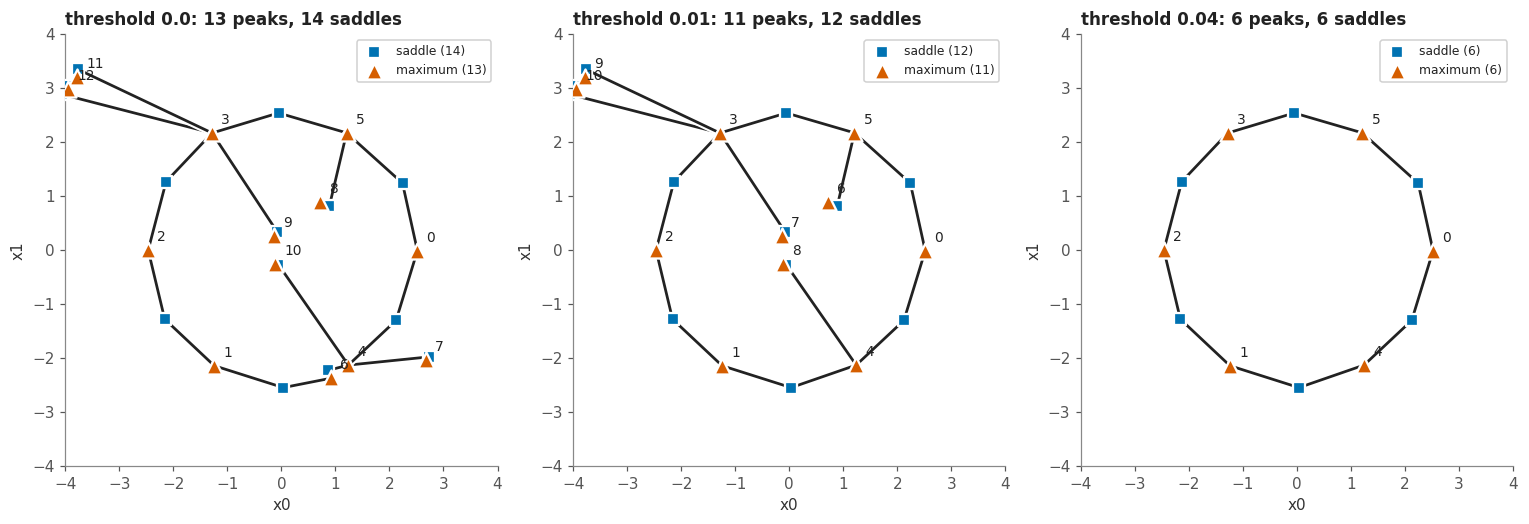

In [11]:
ds = load_dataset("cyclic_2d")
eg10 = extremum_graph(ds.values, knn_graph(ds.points, k=10))
fig, axes = plt.subplots(1, 3, figsize=(14, 4.6))
for ax, t in zip(axes, [0.0, 0.01, 0.04]):
    s = eg10.simplify(t) if t > 0 else eg10
    draw_on_data(ax, ds, s, points=False, title=f"threshold {t}: {s.num_peaks} peaks, {s.num_saddles} saddles")
    ax.set_xlim(-4, 4); ax.set_ylim(-4, 4)
plt.tight_layout(); plt.show()

## 4. The same in 3D (`cyclic_3d`)

The ring now lives in 3D. The code did not change: the extremum graph only
needs the neighbour graph, not the dimension.

In [12]:
ds3 = load_dataset("cyclic_3d")
eg3 = extremum_graph(ds3.values, knn_graph(ds3.points, k=20)).simplify(THRESHOLD)
print(ds3); print(eg3)
compare_with_truth(ds3, eg3)

Dataset('cyclic_3d', mode=cyclic_ring, N=50000, d=3, values=[0.000, 1.000], ground_truth: 6 max, 6 saddle)
ExtremumGraph(6 peaks, 6 saddles (1 close a loop), N=50000)
maximum  truth id   truth location        nearest found point   distance (first 3 coordinates shown)
         max_0      [2.5 0.  0. ]           [ 2.5  -0.02  0.12]     0.121
         max_1      [1.25 2.17 0.  ]        [ 1.22  2.15 -0.13]     0.132
         max_2      [-1.25  2.17  0.  ]     [-1.2   2.11  0.07]     0.098
         max_3      [-2.5  0.   0. ]        [-2.45 -0.03  0.02]     0.061
         max_4      [-1.25 -2.17  0.  ]     [-1.24 -2.14 -0.27]     0.267
         max_5      [ 1.25 -2.17  0.  ]     [ 1.31 -2.17  0.  ]     0.056
saddle   truth id   truth location        nearest found point   distance (first 3 coordinates shown)
         saddle_0   [2.17 1.25 0.  ]        [ 2.13  1.11 -0.04]     0.145
         saddle_1   [0.  2.5 0. ]           [-0.09  2.54 -0.16]     0.187
         saddle_2   [-2.17  1.25  0.  ]

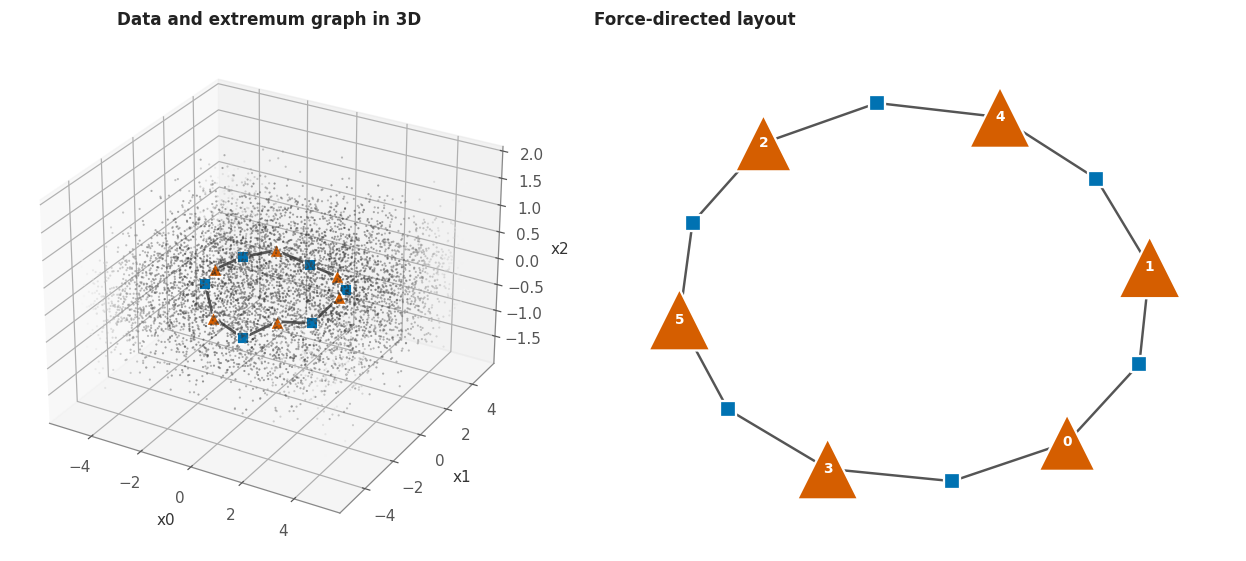

In [13]:
fig = plt.figure(figsize=(12, 5.2))
ax = fig.add_subplot(1, 2, 1, projection="3d")
P = ds3.points
sub = np.random.default_rng(0).choice(len(P), 6000, replace=False)
ax.scatter(*P[sub].T, c=ds3.values[sub], cmap="Greys", s=2, vmin=0, vmax=1.15, alpha=0.5, linewidths=0)
for p, s in eg3.edges:
    a, b = P[eg3.peaks[p]], P[eg3.saddles[s]]
    ax.plot(*zip(a, b), color=LINK, lw=1.8)
ax.scatter(*P[eg3.saddles].T, marker="s", s=60, c=SADDLE, edgecolors="white", linewidths=1.2, depthshade=False)
ax.scatter(*P[eg3.peaks].T, marker="^", s=90, c=PEAK, edgecolors="white", linewidths=1.2, depthshade=False)
ax.set_title("Data and extremum graph in 3D"); ax.set_xlabel("x0"); ax.set_ylabel("x1"); ax.set_zlabel("x2")
ax.view_init(elev=28, azim=-60)
draw_networkx(fig.add_subplot(1, 2, 2), eg3, layout="spring", title="Force-directed layout")
plt.tight_layout(); plt.show()

## 5. Controlled extrema (`ext_2d_small`, `ext_3d`)

These fields are built from Gaussian bumps placed at chosen centres, so the
designed maxima are known. Which of the found peaks are the designed ones?

In [14]:
def match_maxima(name, k=20, threshold=0.05):
    ds = load_dataset(name)
    eg = extremum_graph(ds.values, knn_graph(ds.points, k)).simplify(threshold)
    print(f"{ds}\n{eg}\n")
    print("found peak  value  persistence  nearest designed maximum  distance")
    for i, v in enumerate(eg.peaks):
        d = np.linalg.norm(ds.centers("max") - ds.points[v], axis=1)
        j = int(np.argmin(d))
        pers = "inf" if np.isinf(eg.peak_persistence[i]) else f"{eg.peak_persistence[i]:.3f}"
        tag = f"{ds.maxima[j].id}   {d[j]:.2f}" + ("" if d[j] < 0.6 else "   <- not a designed maximum")
        print(f"     {i}      {eg.peak_values[i]:.3f}   {pers:>6}      {tag}")
    return ds, eg

ds2, eg2 = match_maxima("ext_2d_small")

Dataset('ext_2d_small', mode=controlled_extrema, N=5000, d=2, values=[0.000, 1.000], ground_truth: 3 max, 3 min, 2 saddle)
ExtremumGraph(5 peaks, 6 saddles (2 close a loop), N=5000)

found peak  value  persistence  nearest designed maximum  distance
     0      1.000      inf      max_2   0.04
     1      0.945    0.486      max_1   0.09
     2      0.843    0.168      max_0   0.09
     3      0.620    0.103      max_2   3.29   <- not a designed maximum
     4      0.562    0.103      max_2   4.74   <- not a designed maximum


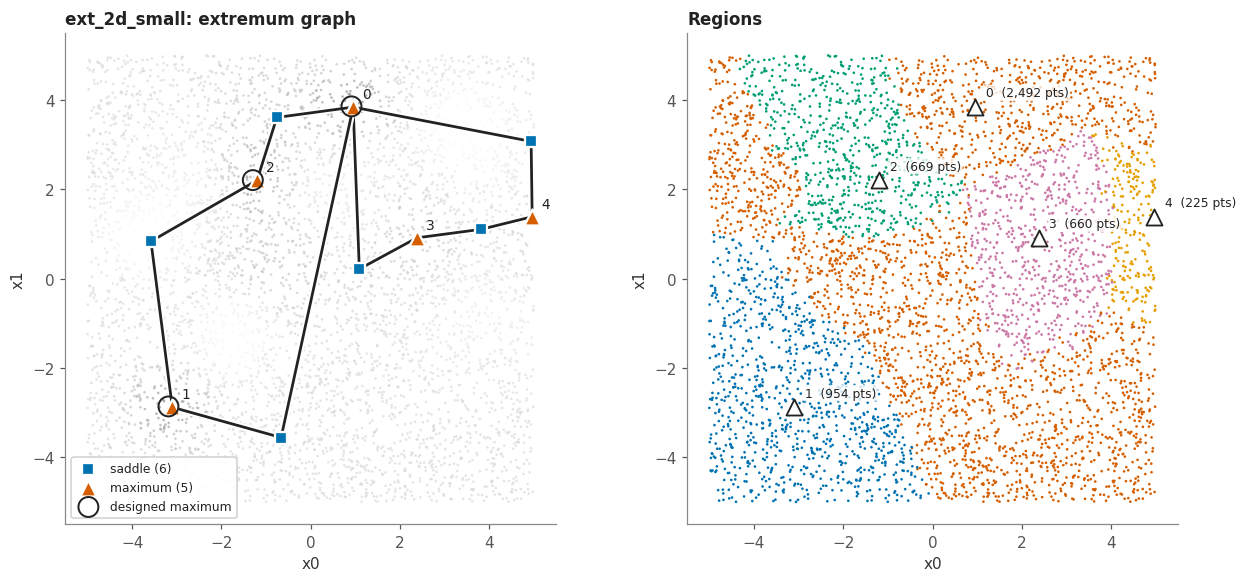

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5.4))
draw_on_data(axes[0], ds2, eg2, title="ext_2d_small: extremum graph")
axes[0].scatter(*ds2.centers("max").T, marker="o", s=170, facecolors="none", edgecolors="#222222",
                linewidths=1.3, zorder=6, label="designed maximum")
axes[0].legend(loc="lower left", fontsize=8, framealpha=0.9)
draw_regions(axes[1], ds2, eg2, title="Regions")
plt.tight_layout(); plt.show()

In [16]:
ds3b, eg3b = match_maxima("ext_3d")

Dataset('ext_3d', mode=controlled_extrema, N=20000, d=3, values=[0.000, 1.000], ground_truth: 4 max, 4 min, 3 saddle)
ExtremumGraph(6 peaks, 11 saddles (6 close a loop), N=20000)

found peak  value  persistence  nearest designed maximum  distance
     0      1.000      inf      max_2   8.55   <- not a designed maximum
     1      0.962    0.421      max_2   0.15
     2      0.910    0.414      max_0   0.28
     3      0.892    0.102      max_1   8.12   <- not a designed maximum
     4      0.735    0.210      max_3   0.29
     5      0.674    0.179      max_1   0.20


All designed maxima are found, each within 0.3 of its centre. Each dataset
also has two further peaks, and in `ext_3d` one of them is the global
maximum. Apart from the global one they have persistence of about 0.1, so
they are not noise and they survive `simplify(0.05)`.

They lie 1.1 to 2.4 from a designed saddle, about one window width (the
generator windows its saddle terms at twice `width`, which is 1.2 in 2D and
1.6 in 3D). A quadratic with both signs rises along some directions until
the window cuts it off, so the saddle term adds bumps beside the saddle.
In `ext_2d_small` the two extra peaks lie on the x axis through the saddle,
the direction in which its quadratic rises. I measured these distances but
did not evaluate the generator's field to confirm the cause.

## 6. Ten dimensions (`cyclic_10d`)

The same ring with 100,000 points in 10 dimensions. The ring lies in the
first two coordinates, and the other eight only pull the values down away
from it. Nothing in the code depends on the dimension.

The ring peaks are less pronounced here than in 2D, so the threshold from
before (0.04) would be too high. The persistence plot shows where to cut:
the five ring peaks stand far above all the noise peaks.

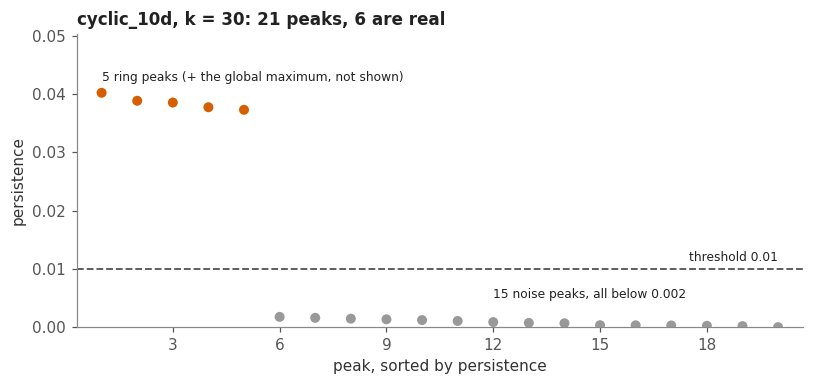

In [17]:
ds10 = load_dataset("cyclic_10d")
eg10d = extremum_graph(ds10.values, knn_graph(ds10.points, k=30))
pers = np.sort(eg10d.peak_persistence[np.isfinite(eg10d.peak_persistence)])[::-1]
THRESHOLD_10D = 0.01

fig, ax = plt.subplots(figsize=(7.5, 3.6))
ax.scatter(np.arange(1, len(pers) + 1), pers, s=60, c=np.where(pers >= THRESHOLD_10D, PEAK, "#999999"),
           edgecolors="white", linewidths=1.2, zorder=3)
ax.axhline(THRESHOLD_10D, color=LINK, lw=1.2, ls="--")
ax.text(len(pers), THRESHOLD_10D + 0.0008, f"threshold {THRESHOLD_10D}", ha="right", va="bottom", fontsize=8)
ax.text(1.0, pers[0] + 0.0015, "5 ring peaks (+ the global maximum, not shown)", fontsize=8, va="bottom")
ax.text(len(pers) / 2 + 2, 0.005, f"{int((pers < THRESHOLD_10D).sum())} noise peaks, all below 0.002", fontsize=8)
ax.xaxis.set_major_locator(plt.MaxNLocator(integer=True))
ax.set_xlabel("peak, sorted by persistence"); ax.set_ylabel("persistence")
ax.set_title(f"cyclic_10d, k = 30: {eg10d.num_peaks} peaks, 6 are real")
ax.set_xlim(0.3, len(pers) + 0.7); ax.set_ylim(0, pers[0] * 1.25)
plt.tight_layout(); plt.show()

In [18]:
sweep_k("cyclic_10d", [10, 20, 30, 40, 80], threshold=THRESHOLD_10D)

cyclic_10d: truth is 6 peaks, 6 saddles (threshold 0.01)
   k   raw peaks  raw saddles  ->  peaks  saddles  same edges as truth


  10        177         3751  ->      8       14  False


  20         44          407  ->      6        6  True


  30         21           97  ->      6        6  True


  40         12           30  ->      6        6  True


  80          9           16  ->      6        6  True


maximum  truth id   truth location        nearest found point   distance (first 3 coordinates shown)
         max_0      [2.5 0.  0. ]           [ 2.69 -0.01  0.02]     0.536
         max_1      [1.25 2.17 0.  ]        [1.09 2.13 0.2 ]        0.517
         max_2      [-1.25  2.17  0.  ]     [-1.35  2.2  -0.25]     0.468
         max_3      [-2.5  0.   0. ]        [-2.59  0.06 -0.28]     0.644
         max_4      [-1.25 -2.17  0.  ]     [-1.25 -2.12  0.37]     0.538
         max_5      [ 1.25 -2.17  0.  ]     [ 1.21 -2.   -0.2 ]     0.506
saddle   truth id   truth location        nearest found point   distance (first 3 coordinates shown)
         saddle_0   [2.17 1.25 0.  ]        [ 2.33  0.85 -0.51]     1.247
         saddle_1   [0.  2.5 0. ]           [-0.54  2.17  0.98]     1.713
         saddle_2   [-2.17  1.25  0.  ]     [-2.17  0.83  0.19]     0.887
         saddle_3   [-2.17 -1.25  0.  ]     [-1.74 -1.43  0.24]     0.932
         saddle_4   [ 0.  -2.5  0. ]        [ 0.34 -2.41  

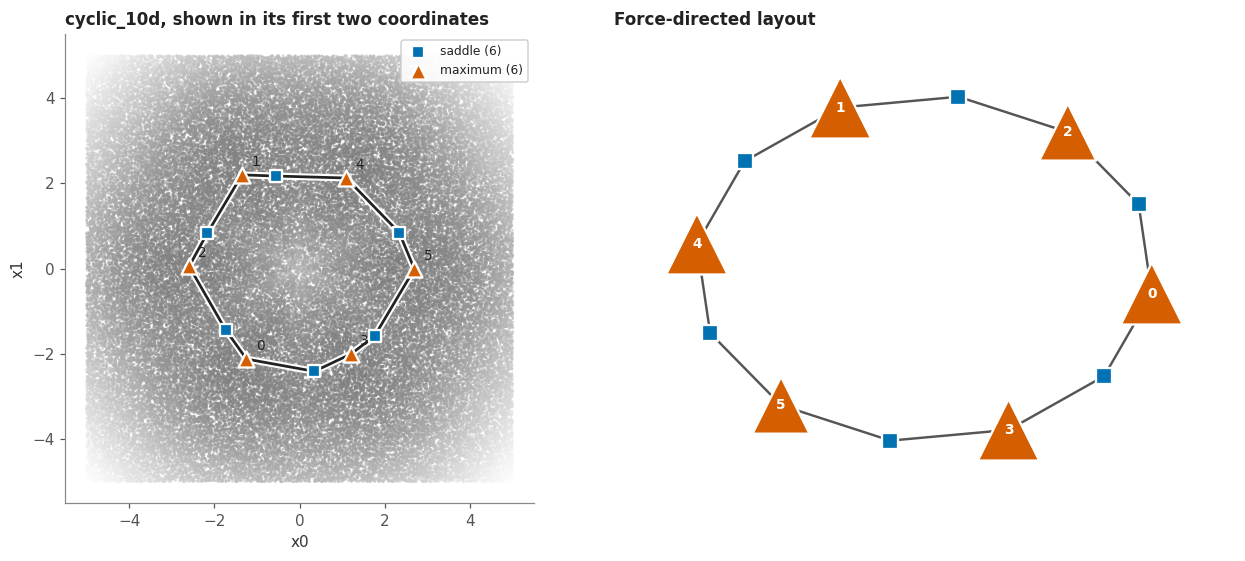

In [19]:
s10 = eg10d.simplify(THRESHOLD_10D)
compare_with_truth(ds10, s10)
fig, axes = plt.subplots(1, 2, figsize=(12, 5.2))
draw_on_data(axes[0], ds10, s10, title="cyclic_10d, shown in its first two coordinates")
draw_networkx(axes[1], s10, layout="spring", title="Force-directed layout")
plt.tight_layout(); plt.show()

For `k` of 20 or more the 10D ring comes out as exactly six peaks and six
saddles, with all twelve links matching the ground truth. At `k = 10` extra
saddles remain, as in the 2D and 3D rings.

**A caveat for the other high-dimensional datasets.** The code runs in about
a second for 100,000 points, but `ext_10d`, `ext_50d` and `ext_100d` cannot
be checked against their designed maxima. With so few samples in so many
dimensions, almost none land near the designed bumps (in `ext_50d` and
`ext_100d` no sample is within two bump widths of any designed maximum), so
the designed maxima are not in the data. The `cyclic_*` datasets are the
usable high-dimensional test because the ring is where the samples are.

## Notes

- **Saddles are data points.** The saddle's position and value are those of a
  sample, so they are only as precise as the sampling.
- **Regions** come from always stepping to the highest neighbour.
  `eg.region[i]` is the peak id of point `i`, and `eg.region_size` counts
  the points per peak.
- **Persistence threshold.** `simplify(t)` merges every peak with persistence
  below `t` into the peak that absorbs it and re-attaches its saddles. This
  is what the front-end slider will call.